# 01 — EDA & Data Cleaning
**Lumen Data Science — Cross-Sell & Up-Sell Prediction**

Ovaj notebook pokriva:
1. Učitavanje i osnovni pregled podataka
2. Analizu stupaca — što zadržati, što baciti
3. Analizu nedostajućih vrijednosti
4. Čišćenje redova i outliera
5. Enkodiranje kategoričkih varijabli
6. Inženjering novih značajki (feature engineering)
7. Spremanje očišćenog dataseta

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams['figure.figsize'] = (12, 5)
sns.set_theme(style='whitegrid')

print('Libraries loaded ✓')

Matplotlib is building the font cache; this may take a moment.


Libraries loaded ✓


---
## 1. Učitavanje podataka


In [2]:
import os

raw_path = '../data/raw/LUMEN_DS.csv'
converted_path = '../data/raw/data.csv'

if not os.path.exists(converted_path):
    with open(raw_path, 'r', encoding='utf-16') as file:
        data = file.read()
    
    data = data.replace('"', '')
    
    with open(converted_path, 'w', encoding='utf-8') as file:
        file.write(data)
    
    print('Konverzija gotova -> data.csv')
else:
    print('data.csv već postoji, preskačem konverziju')

Konverzija gotova -> data.csv


In [3]:
DATE_COLS = [
    'Invoice Date',
    'Order Date',
    'Customer First Invoice Date',
    'Price last modified date in the ERP',
    'Born on date'
]

df_raw = pd.read_csv(
    '../data/raw/data.csv',
    encoding='utf-8',
    sep='|',
    low_memory=False,
    parse_dates=DATE_COLS
)

print(f'Shape: {df_raw.shape}')
print(f'Redova: {df_raw.shape[0]:,} | Stupaca: {df_raw.shape[1]}')
df_raw.head(3)

Shape: (1294962, 33)
Redova: 1,294,962 | Stupaca: 33


,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Price last modified date in the ERP,Born on date,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Sales Channel - Grouping,Invoice Date,Invoice #,Invoice Line #,Order Date,Order #,Order Line #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,Material cost of part,Labor cost of part,Overhead cost of part,GM%,# of unique products on a quote
0,North America,N7,YES,224224,IC000,Asia,2009-06-26,OTHER,054501,PF002,NaN,NaT,2012-02-13,BUY,099,099,NaN,2019-08-06,16782381,18645771,2019-08-05,32606.0000,15791584.0000,499.0000,499.0000,0.3900,0.3900,0.4173,0.3900,0.0000,0.0000,-0.0700,1.0000
1,North America,N7,NO,230494,IC012,North America,2007-08-08,OTHER,034903,PF002,PC026,2020-06-22,2009-12-31,BUY,900,900,NaN,2019-11-26,16808190,18670413,2019-11-24,82915.0000,15806968.0000,1000.0000,1000.0000,0.1400,0.1400,0.0257,0.0240,0.0000,0.0000,0.8164,3.0000
2,Asia,N13,YES,235861,IC000,North America,2008-02-07,OTHER,057280,PF002,NaN,NaT,2017-01-03,MANUFACTURED,RS-NH,RS-NH,NaN,2019-09-24,16790722,18655474,2019-09-03,32787.0000,15795161.0000,3.0000,3.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,14.0000


In [4]:
already_dropped = [
    'Invoice Line #', 'Order Date', 'Ordered qty',
    'Material cost of part', 'Labor cost of part', 'Overhead cost of part',
    'Sales Channel - Grouping', 'Born on date',
    'Price last modified date in the ERP',
    '# of unique products on a quote', 'Order Line #', 'Order #'
]

display(df_raw[already_dropped].head(20))

,Invoice Line #,Order Date,Ordered qty,Material cost of part,Labor cost of part,Overhead cost of part,Sales Channel - Grouping,Born on date,Price last modified date in the ERP,# of unique products on a quote,Order Line #,Order #
0,18645771,2019-08-05,499.0000,0.3900,0.0000,0.0000,NaN,2012-02-13,NaT,1.0000,15791584.0000,32606.0000
1,18670413,2019-11-24,1000.0000,0.0240,0.0000,0.0000,NaN,2009-12-31,2020-06-22,3.0000,15806968.0000,82915.0000
2,18655474,2019-09-03,3.0000,0.0000,0.0000,0.0000,NaN,2017-01-03,NaT,14.0000,15795161.0000,32787.0000
3,18688647,2020-03-10,5000.0000,0.0000,0.0000,0.0000,NaN,2014-12-02,NaT,1.0000,15818226.0000,98093.0000
4,18688639,2020-03-10,5000.0000,0.0000,0.0000,0.0000,NaN,2014-12-02,NaT,1.0000,15818226.0000,98093.0000
5,18687466,2020-03-10,5000.0000,0.0000,0.0000,0.0000,NaN,2014-12-02,NaT,1.0000,15818226.0000,98093.0000
6,18581670,2018-07-06,4000.0000,0.0000,0.0000,0.0000,NaN,2014-12-09,NaT,6.0000,15736930.0000,513470.0000
7,18717648,2019-11-18,15000.0000,0.0000,0.0000,0.0000,NaN,2014-02-12,NaT,1.0000,15805892.0000,73572.0000
8,18678512,2019-12-05,500.0000,0.0000,0.0000,0.0000,NaN,2014-07-18,NaT,1.0000,15808552.0000,91617.0000
9,18632400,2019-01-14,2000.0000,0.0000,0.0000,0.0000,NaN,2015-07-21,NaT,2.0000,15764662.0000,526717.0000


---
## 2. Osnovni pregled — dtypes, nullovi, unike

In [9]:
# Pregled svakog stupca: dtype, % nullova, broj unikatnih vrijednosti
summary = pd.DataFrame({
    'dtype': df_raw.dtypes,
    'null_count': df_raw.isnull().sum(),
    'null_%': (df_raw.isnull().sum() / len(df_raw) * 100).round(2),
    'n_unique': df_raw.nunique(),
    'sample_value': df_raw.iloc[0],
    'zero': df_raw.eq(0).sum(),
    'zero_%': (df_raw.eq(0).sum() / len(df_raw) * 100).round(2)
})
display(summary)

,dtype,null_count,null_%,n_unique,sample_value,zero,zero_%
Manufacturing Region,object,40509,3.1300,3,North America,0,0.0000
Manufacturing Location Code,object,39959,3.0900,29,N7,0,0.0000
Intercompany,object,0,0.0000,2,YES,0,0.0000
CustomerID,int64,0,0.0000,12214,224224,0,0.0000
Customer industry,object,0,0.0000,15,IC000,0,0.0000
Customer Region,object,103,0.0100,3,Asia,0,0.0000
Customer First Invoice Date,datetime64[ns],0,0.0000,4232,2009-06-26 00:00:00,0,0.0000
Top Customer Group,object,0,0.0000,2,OTHER,0,0.0000
Item Code,object,55,0.0000,63019,054501,0,0.0000
Product family,object,0,0.0000,3,PF002,0,0.0000


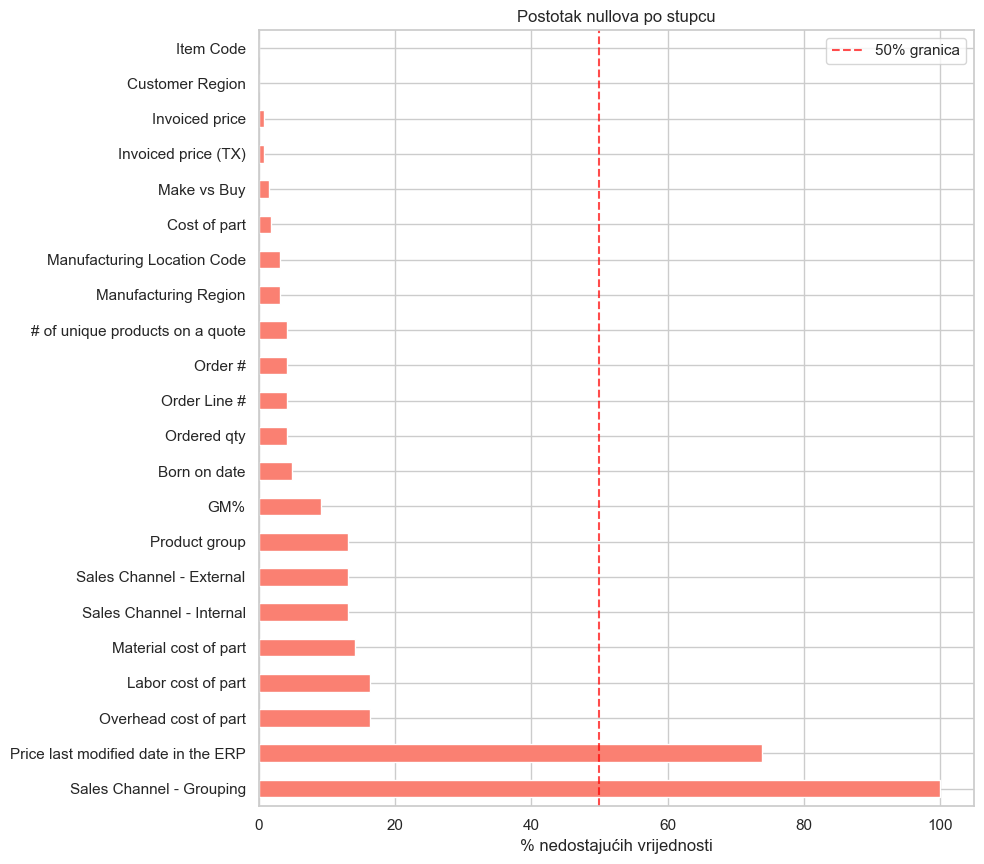

In [10]:
# Vizualizacija % nullova po stupcu
null_pct = (df_raw.isnull().sum() / len(df_raw) * 100).sort_values(ascending=False)
null_pct = null_pct[null_pct > 0]

if len(null_pct) > 0:
    fig, ax = plt.subplots(figsize=(10, max(4, len(null_pct) * 0.4)))
    null_pct.plot(kind='barh', ax=ax, color='salmon')
    ax.set_xlabel('% nedostajućih vrijednosti')
    ax.set_title('Postotak nullova po stupcu')
    ax.axvline(50, color='red', linestyle='--', alpha=0.7, label='50% granica')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Nema nullova — provjeri jesu li prazni stringovi umjesto NaN!')

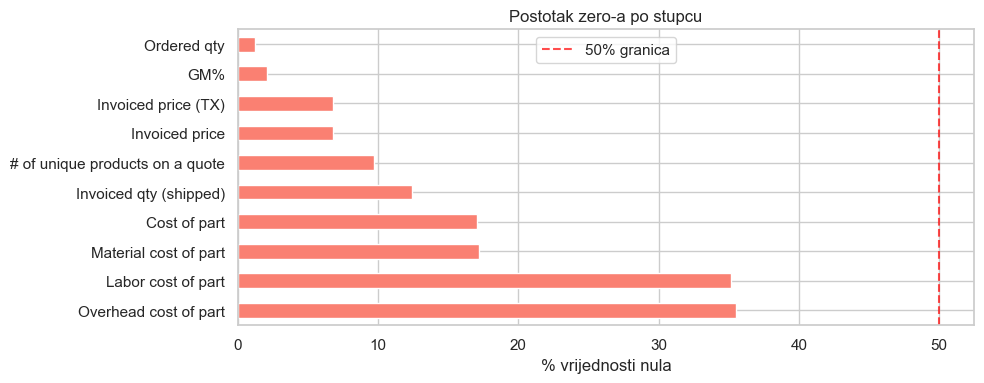

In [12]:
# Vizualizacija % zero-a po stupcu
zero_pct = (df_raw.eq(0).sum() / len(df_raw) * 100).sort_values(ascending=False)
zero_pct = zero_pct[zero_pct > 0]

if len(zero_pct) > 0:
    fig, ax = plt.subplots(figsize=(10, max(4, len(zero_pct) * 0.4)))
    zero_pct.plot(kind='barh', ax=ax, color='salmon')
    ax.set_xlabel('% vrijednosti nula')
    ax.set_title('Postotak zero-a po stupcu')
    ax.axvline(50, color='red', linestyle='--', alpha=0.7, label='50% granica')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Nema zero-a!')

In [13]:
# Provjeri prazne stringove (čest problem u ovom datasetu)
empty_str = (df_raw == '').sum()
empty_str = empty_str[empty_str > 0]
print('Stupci s praznim stringovima:')
print(empty_str.sort_values(ascending=False))

Stupci s praznim stringovima:
Series([], dtype: int64)


---
## 3. Uklanjanje stupaca (nastavak od cleaner.py)

Prijateljev cleaner.py već je uklonio stupce koji su redudantni ili previše granularni.
Ovdje razmatramo treba li još nešto ukloniti.

In [14]:
# Stupci koje je cleaner.py uklonio, ali malo editano
already_dropped = [
    'Invoice Line #', 'Order Date',
    'Material cost of part', 'Labor cost of part', 'Overhead cost of part',
    'Sales Channel - Grouping', 'Born on date',
    'Price last modified date in the ERP', 'Order Line #'
]

# Primijeni drop (samo ako stupci postoje u df_raw)
cols_to_drop = [c for c in already_dropped if c in df_raw.columns]
df = df_raw.drop(columns=cols_to_drop)
print(f'Nakon inicijalnog dropa: {df.shape}')

Nakon inicijalnog dropa: (1294962, 24)


In [15]:
# --- ANALIZA PREOSTALIH STUPACA ---
# Pogledaj kardinalnost kategoričkih stupaca
cat_cols = df.select_dtypes(include='object').columns.tolist()

for col in cat_cols:
    vc = df[col].value_counts(dropna=False)
    print(f'\n=== {col} ({df[col].nunique()} unikatnih) ===')
    print(vc.head(10))


=== Manufacturing Region (3 unikatnih) ===
Manufacturing Region
North America    734815
Asia             464038
Europe            55600
NaN               40509
Name: count, dtype: int64

=== Manufacturing Location Code (29 unikatnih) ===
Manufacturing Location Code
B6     199828
B8     151245
N13    124771
B77    103285
B20     99905
B70     89945
L1      67043
L2      59951
B3      54164
B76     46967
Name: count, dtype: int64

=== Intercompany (2 unikatnih) ===
Intercompany
NO     1103993
YES     190969
Name: count, dtype: int64

=== Customer industry (15 unikatnih) ===
Customer industry
IC000    453233
IC007    183975
IC008    175248
IC003    103123
IC005     96904
IC004     64220
IC011     59069
IC010     49535
IC009     37024
IC002     28634
Name: count, dtype: int64

=== Customer Region (3 unikatnih) ===
Customer Region
North America    773408
Asia             439883
Europe            81568
NaN                 103
Name: count, dtype: int64

=== Top Customer Group (2 unikatnih) =

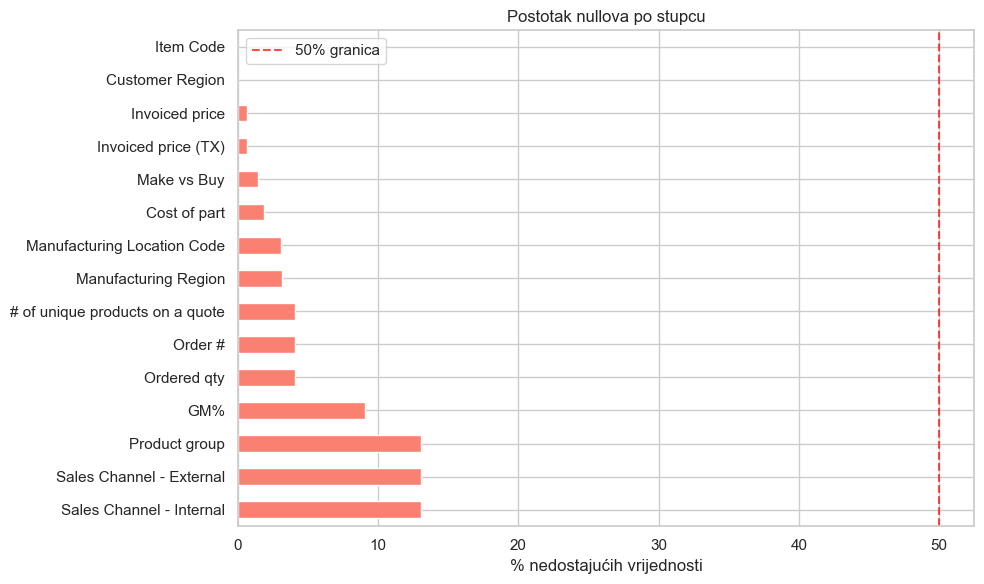

In [16]:
# Vizualizacija % nullova po stupcu
null_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
null_pct = null_pct[null_pct > 0]

if len(null_pct) > 0:
    fig, ax = plt.subplots(figsize=(10, max(4, len(null_pct) * 0.4)))
    null_pct.plot(kind='barh', ax=ax, color='salmon')
    ax.set_xlabel('% nedostajućih vrijednosti')
    ax.set_title('Postotak nullova po stupcu')
    ax.axvline(50, color='red', linestyle='--', alpha=0.7, label='50% granica')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Nema nullova — provjeri jesu li prazni stringovi umjesto NaN!')

In [17]:
# Intercompany transakcije — treba li ih filtrirati?
# Intercompany = YES znači prodaja unutar iste korporacije, ne pravi kupac
print('Raspodjela Intercompany:')
print(df['Intercompany'].value_counts())
print(f'\n% Intercompany=YES: {(df["Intercompany"]=="YES").mean()*100:.1f}%')

# ODLUKA: Filtriraj intercompany van za cross-sell model
# (ostavi ih za posebnu analizu ako treba)
df_external = df[df['Intercompany'] == 'NO'].copy()
print(f'\nNakon filtriranja Intercompany=YES: {df_external.shape}')

Raspodjela Intercompany:
Intercompany
NO     1103993
YES     190969
Name: count, dtype: int64

% Intercompany=YES: 14.7%

Nakon filtriranja Intercompany=YES: (1103993, 24)


In [18]:
# Sales Channel - Internal vs External — jesu li isti?
same_channel = (df['Sales Channel - Internal'] == df['Sales Channel - External']).mean()
print(f'% redova gdje su Internal == External kanal: {same_channel*100:.1f}%')
# Ako je > 95%, jedan od njih je redundantan

# PRIJEDLOG: ako su gotovo uvijek isti, zadrži samo Internal i dropaj External
# df = df.drop(columns=['Sales Channel - External'])  # odkomentiraj ako potvrdiš

% redova gdje su Internal == External kanal: 86.9%


In [19]:
display(df[['Sales Channel - Internal', 'Sales Channel - External']].head(20))

,Sales Channel - Internal,Sales Channel - External
0,099,099
1,900,900
2,RS-NH,RS-NH
3,230,230
4,230,230
5,230,230
6,230,230
7,11103,11103
8,11103,11103
9,DG_0029,DG_0029


In [20]:
# Manufacturing Location Code vs Manufacturing Region — hijerarhija?
print(df.groupby('Manufacturing Region')['Manufacturing Location Code'].nunique())
# Ako Region ima malo unikata a Location Code mnogo — Location Code je granularniji
# Za modele često je dovoljno Region razina

Manufacturing Region
Asia             11
Europe            3
North America    14
Name: Manufacturing Location Code, dtype: int64


---
## 4. Čišćenje redova

In [22]:
df_4 = df_external.copy()

print(df_4.columns.tolist())

['Manufacturing Region', 'Manufacturing Location Code', 'Intercompany', 'CustomerID', 'Customer industry', 'Customer Region', 'Customer First Invoice Date', 'Top Customer Group', 'Item Code', 'Product family', 'Product group', 'Make vs Buy', 'Sales Channel - Internal', 'Sales Channel - External', 'Invoice Date', 'Invoice #', 'Order #', 'Invoiced qty (shipped)', 'Ordered qty', 'Invoiced price', 'Invoiced price (TX)', 'Cost of part', 'GM%', '# of unique products on a quote']


In [23]:
# Pregled svakog stupca: dtype, % nullova, broj unikatnih vrijednosti
summary_4 = pd.DataFrame({
    'dtype': df_4.dtypes,
    'null_count': df_4.isnull().sum(),
    'null_%': (df_4.isnull().sum() / len(df_4) * 100).round(2),
    'n_unique': df_4.nunique(),
    'sample_value': df_4.iloc[0],
    'zero': df_4.eq(0).sum(),
    'zero_%': (df_4.eq(0).sum() / len(df_4) * 100).round(2)
})
display(summary)

,dtype,null_count,null_%,n_unique,sample_value,zero,zero_%
Manufacturing Region,object,40509,3.1300,3,North America,0,0.0000
Manufacturing Location Code,object,39959,3.0900,29,N7,0,0.0000
Intercompany,object,0,0.0000,2,YES,0,0.0000
CustomerID,int64,0,0.0000,12214,224224,0,0.0000
Customer industry,object,0,0.0000,15,IC000,0,0.0000
Customer Region,object,103,0.0100,3,Asia,0,0.0000
Customer First Invoice Date,datetime64[ns],0,0.0000,4232,2009-06-26 00:00:00,0,0.0000
Top Customer Group,object,0,0.0000,2,OTHER,0,0.0000
Item Code,object,55,0.0000,63019,054501,0,0.0000
Product family,object,0,0.0000,3,PF002,0,0.0000


In [24]:
# 4a. Ukloni redove bez ključnih identifikatora
before = len(df_4)
df = df_4.dropna(subset=['Item Code', 'CustomerID'])
print(f'Uklonjeno zbog null ključnih stupaca: {before - len(df)} redova')

Uklonjeno zbog null ključnih stupaca: 50 redova


In [25]:
df_4 = df_4.dropna(subset=['Item Code', 'CustomerID'])
print(f'Uklonjeno zbog null ključnih stupaca: {before - len(df_4)} redova')

Uklonjeno zbog null ključnih stupaca: 50 redova


In [26]:
# Koliko item codeova koji imaju null cijenu postoje negdje drugdje s cijenom?
null_price_items = df_4[df_4['Invoiced price'].isna()]['Item Code'].unique()
has_price_elsewhere = df_4[
    df_4['Item Code'].isin(null_price_items) & df_4['Invoiced price'].notna()
]['Item Code'].nunique()

print(f'Item codeova s null cijenom: {len(null_price_items)}')
print(f'Od toga, koliko ih ima cijenu negdje drugdje: {has_price_elsewhere}')

Item codeova s null cijenom: 30
Od toga, koliko ih ima cijenu negdje drugdje: 10


In [31]:
# Imputiraj Invoiced price medianom po Item Code gdje je moguće
median_price_by_item = df_4.groupby('Item Code')['Invoiced price'].median()
df_4['Invoiced price'] = df_4.apply(
    lambda row: median_price_by_item[row['Item Code']] 
    if pd.isna(row['Invoiced price']) else row['Invoiced price'],
    axis=1
)

null_after = df_4[df_4['Invoiced price'].isna()]['Item Code'].unique()
print(f'Item codeova s null cijenom: {len(null_after)}')

Item codeova s null cijenom: 20


In [33]:
before = len(df_4)
df_4 = df_4.dropna(subset=['Invoiced price'])
print(f'Uklonjeno zbog null Invoiced price: {before - len(df_4)} redova')

Uklonjeno zbog null Invoiced price: 172 redova


In [34]:
print(f'Redova s Invoiced price == 0: {(df_4["Invoiced price"] == 0).sum()}')
print(f'Redova s Invoiced price < 0: {(df_4["Invoiced price"] < 0).sum()}')

Redova s Invoiced price == 0: 60787
Redova s Invoiced price < 0: 549


In [35]:
display(df_4[df_4['Invoiced price'] == 0].head(10))

# Jesu li to specifični sales channeli?
print(df_4[df_4['Invoiced price'] == 0]['Sales Channel - Internal'].value_counts())

# Jesu li to specifični product familiji?
print(df_4[df_4['Invoiced price'] == 0]['Product family'].value_counts())

# Imaju li ti redovi Cost of part?
print(f'% s Cost of part > 0: {(df_4[df_4["Invoiced price"] == 0]["Cost of part"] > 0).mean()*100:.1f}%')

,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Order #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%,# of unique products on a quote
23,Asia,N13,NO,224597,IC007,Asia,2012-03-21,STAR,667081T1,PF002,NaN,MANUFACTURED,DG2_0099,DG2_0099,2019-12-17,16812370,464670.0000,1.0000,1.0000,0.0000,0.0000,215.2714,NaN,399.0000
181,North America,B20,NO,289099,IC007,North America,2009-07-28,OTHER,2-100-000-17838,PF001,NaN,MANUFACTURED,MW,MW,2018-05-30,1292827,587200.0000,0.3000,0.3000,0.0000,0.0000,42.7912,NaN,6.0000
183,North America,B20,NO,284294,IC003,North America,2004-06-16,OTHER,2-120-000-11983,PF001,PC010,MANUFACTURED,H,H,2018-06-04,1236887,592244.0000,0.0000,0.0500,0.0000,0.0000,672.2857,NaN,2.0000
221,Asia,N13,NO,223862,IC000,Asia,2005-02-22,OTHER,363222,PF002,NaN,BUY,SZ_0083,SZ_0083,2019-10-17,16794784,50241.0000,30.0000,30.0000,0.0000,0.0000,1.4351,NaN,2.0000
227,Asia,N13,NO,231565,IC000,Asia,2004-11-29,OTHER,363097,PF002,NaN,BUY,TW16,TW16,2019-08-30,16994140,30350.0000,450.0000,450.0000,0.0000,0.0000,0.0000,NaN,17.0000
231,Asia,N13,NO,224483,IC000,Asia,2012-07-31,OTHER,622231,PF002,PC002,MANUFACTURED,HK_14468,HK_14468,2019-06-24,16774839,540023.0000,1.0000,1.0000,0.0000,0.0000,0.0000,NaN,3.0000
237,Asia,N13,NO,231565,IC000,Asia,2004-11-29,OTHER,653745,PF002,PC002,MANUFACTURED,TW16,TW16,2018-03-10,16944426,491855.0000,400.0000,400.0000,0.0000,0.0000,0.0000,NaN,2.0000
278,Asia,B77,NO,20774,IC007,Asia,2017-07-20,OTHER,DEL449-0969901,PF001,PC010,MANUFACTURED,B318,B318,2019-11-05,13659285,11979789.0000,0.0000,1000.0000,0.0000,0.0000,0.0000,NaN,1.0000
283,Asia,B77,NO,20665,IC007,Asia,2007-05-30,OTHER,DEL449-22X8H,PF001,PC010,MANUFACTURED,B318,B318,2018-04-23,13509370,11920617.0000,0.0000,3200.0000,0.0000,0.0000,0.0000,NaN,1.0000
285,Asia,B76,NO,19415,IC008,Asia,2014-06-09,OTHER,DEL449-267FK,PF001,PC011,MANUFACTURED,B318,B318,2019-07-23,13297560,11665640.0000,0.0000,2000.0000,0.0000,0.0000,0.0000,NaN,1.0000


Sales Channel - Internal
B318      19928
0092       7702
b116       1959
TTM001     1669
HOUSE      1563
          ...  
b108          1
L204          1
ATM           1
CSC           1
E.C. 3        1
Name: count, Length: 367, dtype: int64
Product family
PF001    36246
PF000    13119
PF002    11422
Name: count, dtype: int64
% s Cost of part > 0: 25.4%


In [36]:
# Istraži B318 kanal
display(df_4[
    (df_4['Invoiced price'] == 0) & 
    (df_4['Sales Channel - Internal'] == 'B318')
].head(10))

# Ima li B318 ikad nenultu cijenu?
print(f'B318 redovi s cijenom > 0: {((df_4["Sales Channel - Internal"] == "B318") & (df_4["Invoiced price"] > 0)).sum()}')

,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Order #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%,# of unique products on a quote
278,Asia,B77,NO,20774,IC007,Asia,2017-07-20,OTHER,DEL449-0969901,PF001,PC010,MANUFACTURED,B318,B318,2019-11-05,13659285,11979789.0000,0.0000,1000.0000,0.0000,0.0000,0.0000,NaN,1.0000
283,Asia,B77,NO,20665,IC007,Asia,2007-05-30,OTHER,DEL449-22X8H,PF001,PC010,MANUFACTURED,B318,B318,2018-04-23,13509370,11920617.0000,0.0000,3200.0000,0.0000,0.0000,0.0000,NaN,1.0000
285,Asia,B76,NO,19415,IC008,Asia,2014-06-09,OTHER,DEL449-267FK,PF001,PC011,MANUFACTURED,B318,B318,2019-07-23,13297560,11665640.0000,0.0000,2000.0000,0.0000,0.0000,0.0000,NaN,1.0000
289,Asia,B76,NO,19425,IC007,Asia,2015-08-12,OTHER,DEL449-2J071S600,PF001,PC010,MANUFACTURED,B318,B318,2019-05-06,15792139,11661885.0000,0.0000,800.0000,0.0000,0.0000,0.0000,NaN,1.0000
291,Asia,B76,NO,19425,IC007,Asia,2015-08-12,OTHER,DEL449-2J071UA00,PF001,PC010,MANUFACTURED,B318,B318,2018-10-28,15452867,11653992.0000,0.0000,500.0000,0.0000,0.0000,0.0000,NaN,1.0000
292,Asia,B76,NO,19425,IC007,Asia,2015-08-12,OTHER,DEL449-2J121EV00,PF001,PC010,MANUFACTURED,B318,B318,2018-12-16,15546318,11656224.0000,0.0000,5000.0000,0.0000,0.0000,0.0000,NaN,1.0000
294,Asia,B76,NO,19427,IC007,Asia,2016-10-28,OTHER,DEL449-34.5Q930,PF001,PC010,MANUFACTURED,B318,B318,2019-06-18,15862378,11662956.0000,0.0000,1728.0000,0.0000,0.0000,0.0000,NaN,1.0000
295,Asia,B76,NO,19425,IC007,Asia,2015-08-12,OTHER,DEL449-3A2140P00,PF001,PC011,MANUFACTURED,B318,B318,2019-10-27,13464210,11670471.0000,0.0000,4800.0000,0.0000,0.0000,0.0000,NaN,1.0000
377,Asia,B76,NO,19427,IC007,Asia,2016-10-28,OTHER,DEL449-H6K25,PF001,PC011,MANUFACTURED,B318,B318,2019-07-02,15895562,11663921.0000,0.0000,1000.0000,0.0000,0.0000,0.0000,NaN,1.0000
707,Asia,B77,NO,20665,IC007,Asia,2007-05-30,OTHER,DEL449-40.58U74H,PF001,PC010,MANUFACTURED,B318,B318,2018-05-23,13519901,11923523.0000,0.0000,100.0000,0.0000,0.0000,0.0000,NaN,1.0000


B318 redovi s cijenom > 0: 30522


In [37]:
# Grupa 1: cijena 0 ali ima trošak — možda vrijedi imputirati
can_impute = df_4[
    (df_4['Invoiced price'] == 0) & 
    (df_4['Cost of part'] > 0)
]
print(f'Redova s cijenom 0 ali s troškom: {len(can_impute)}')

# Grupa 2: cijena 0 i trošak 0 — možda izbaciti
both_zero = df_4[
    (df_4['Invoiced price'] == 0) & 
    (df_4['Cost of part'] == 0)
]
print(f'Redova gdje je i cijena i trošak 0: {len(both_zero)}')

Redova s cijenom 0 ali s troškom: 15434
Redova gdje je i cijena i trošak 0: 42226


In [38]:
# Grupa 1: cijena 0 ali ima trošak, sigurno imputirati cijenu
median_price = df_4.groupby('Item Code')['Invoiced price'].median()

mask = (df_4['Invoiced price'] == 0) & (df_4['Cost of part'] > 0)
df_4.loc[mask, 'Invoiced price'] = df_4.loc[mask, 'Item Code'].map(median_price)
print(f'Imputirano: {mask.sum()} redova')

Imputirano: 15434 redova


In [39]:
# Dodatna provjera ovih 42226 redova gdje je i cijena i trošak 0
both_zero = df_4[(df_4['Invoiced price'] == 0) & (df_4['Cost of part'] == 0)]

# Koji kupci su najzastupljeniji?
print('Top 10 kupaca:')
print(both_zero['CustomerID'].value_counts().head(10))

# Koji item codeovi su najzastupljeniji?
print('\nTop 10 item codeova:')
print(both_zero['Item Code'].value_counts().head(10))

# Koji sales channel?
print('\nSales Channel raspodjela:')
print(both_zero['Sales Channel - Internal'].value_counts().head(10))

# Koji product family?
print('\nProduct family:')
print(both_zero['Product family'].value_counts())

# Jesu li to isti kupci koji imaju i normalne transakcije?
zero_customers = both_zero['CustomerID'].unique()
print(f'\nKupaca koji SAMO imaju nulte transakcije: {len(set(zero_customers) - set(df_4[df_4["Invoiced price"] > 0]["CustomerID"].unique()))}')
print(f'Kupaca koji imaju i nulte I normalne transakcije: {len(set(zero_customers) & set(df_4[df_4["Invoiced price"] > 0]["CustomerID"].unique()))}')

Top 10 kupaca:
CustomerID
20774    4026
19415    3758
19425    3719
20665    3144
2028     2704
2035     2116
20624    1702
2027     1488
20749    1243
19427    1091
Name: count, dtype: int64

Top 10 item codeova:
Item Code
/C                 8319
/LTI               4251
SAMPLE-MPCS         528
SAMPLE-EACH         462
AUSFA               401
*200005             295
205-0121-38         288
DEL449-YC553-1      164
*200007             164
RC045J03BG0C011     151
Name: count, dtype: int64

Sales Channel raspodjela:
Sales Channel - Internal
B318    19003
0092     7690
b116     1811
0056     1460
0036     1171
H        1024
TW16      878
0008      818
41        786
0103      505
Name: count, dtype: int64

Product family:
Product family
PF001    24968
PF000    12955
PF002     4303
Name: count, dtype: int64

Kupaca koji SAMO imaju nulte transakcije: 58
Kupaca koji imaju i nulte I normalne transakcije: 1421


In [40]:
# Označi sample/servisne stavke prije brisanja
sample_items = ['/C', '/LTI', 'SAMPLE-MPCS', 'SAMPLE-EACH']

print('Raspodjela nultih redova:')
print(f'  Sample/servisne stavke: {both_zero["Item Code"].isin(sample_items).sum()}')
print(f'  Ostalo: {(~both_zero["Item Code"].isin(sample_items)).sum()}')

# Provjeri još koji item codeovi izgledaju kao sample/servis
print('\nSvi item codeovi koji sadrže SAMPLE ili / :')
print(both_zero[both_zero['Item Code'].str.contains('SAMPLE|^/', na=False)]['Item Code'].value_counts())

Raspodjela nultih redova:
  Sample/servisne stavke: 13560
  Ostalo: 28666

Svi item codeovi koji sadrže SAMPLE ili / :
Item Code
/C                  8319
/LTI                4251
SAMPLE-MPCS          528
SAMPLE-EACH          462
SAMPLE-ROLLS         126
/EXPEDITE-CUST        72
SAMPLE-LFT            47
SAMPLE-RLS            40
SAMPLE                36
SAMPLES               29
SAMPLE-NEWNAN         28
/CHARGE               26
/INVADJ               16
SAMPLE DEBIT          10
/ENGINEERING-N         7
/PP&ADD FREIGHT        4
/M                     4
/C01                   3
/TOOLING               3
B6-SAMPLE LCUT         2
B6-SAMPLE STOCK        2
SAMPLE-ECOLAB          2
/PKG1                  1
//C01                  1
FREE SAMPLE            1
SAMPLE-CONEXICON       1
SAMPLE-WAVEFORM        1
/C03                   1
SAMPLE-STRYKER         1
/EXPEDITE-LTI          1
SAMPLE-HALYARD         1
Name: count, dtype: int64


In [41]:
other_zero = both_zero[~both_zero['Item Code'].str.contains('SAMPLE|^/', na=False)]

print('Top 20 item codeova u "ostalo" grupi:')
print(other_zero['Item Code'].value_counts().head(20))

print('\nTop 10 kupaca u "ostalo" grupi:')
print(other_zero['CustomerID'].value_counts().head(10))

print('\nMake vs Buy raspodjela:')
print(other_zero['Make vs Buy'].value_counts())

print('\nIma li ordered qty > 0?')
print(f'Redova s Ordered qty > 0: {(other_zero["Ordered qty"] > 0).sum()}')
print(f'Redova s Ordered qty == 0: {(other_zero["Ordered qty"] == 0).sum()}')

Top 20 item codeova u "ostalo" grupi:
Item Code
AUSFA               401
*200005             295
205-0121-38         288
DEL449-YC553-1      164
*200007             164
RC045J03BG0C011     151
DEL449-1051501-9    122
DEL449-31FGN-1      119
DEL449-1888601      118
DEL449-7B174FR-2    117
DEL449-B1803801     115
DEL449-3MT28-701    113
DEL449-1804401      108
205-0121-37         106
DEL449-2J054ES00    101
DEL449-7B174FT-1    101
DEL449-1804001       98
DEL449-2J054F000     97
DEL449-1895201       97
*300009              94
Name: count, dtype: int64

Top 10 kupaca u "ostalo" grupi:
CustomerID
20774     4026
19415     3758
19425     3719
20665     3144
20624     1702
20749     1243
19427     1091
231565     837
245638     730
19435      724
Name: count, dtype: int64

Make vs Buy raspodjela:
Make vs Buy
MANUFACTURED            25228
BUY                      1652
BUY - LOCAL               639
BUY - IMPORTED            627
BUY - CUST. SUPPLIED       35
FINISHED GOODS              9
Name: cou

In [42]:
# DEL449 prefix - što su to?
del449 = other_zero[other_zero['Item Code'].str.startswith('DEL449')]
print(f'DEL449 redova: {len(del449)}')
print(f'DEL449 kupaca: {del449["CustomerID"].nunique()}')
print(f'DEL449 - ima li ih s cijenom > 0 u glavnom datasetu?')
del449_with_price = df_4[
    df_4['Item Code'].str.startswith('DEL449') & 
    (df_4['Invoiced price'] > 0)
]
print(f'DEL449 redova s cijenom > 0: {len(del449_with_price)}')

# AUSFA, *200005 - što su?
print('\nAUSFA Make vs Buy:')
print(other_zero[other_zero['Item Code'] == 'AUSFA']['Make vs Buy'].value_counts())
print('\n*200005 Make vs Buy:')
print(other_zero[other_zero['Item Code'] == '*200005']['Make vs Buy'].value_counts())

# Kupci 20774, 19415, 19425 - dominiraju, jesu li to isti B318 kanal?
print('\nTop kupci - koji kanal koriste?')
print(other_zero[other_zero['CustomerID'].isin([20774, 19415, 19425])]['Sales Channel - Internal'].value_counts())

DEL449 redova: 18782
DEL449 kupaca: 19
DEL449 - ima li ih s cijenom > 0 u glavnom datasetu?
DEL449 redova s cijenom > 0: 29509

AUSFA Make vs Buy:
Make vs Buy
MANUFACTURED    401
Name: count, dtype: int64

*200005 Make vs Buy:
Make vs Buy
BUY - LOCAL    295
Name: count, dtype: int64

Top kupci - koji kanal koriste?
Sales Channel - Internal
B318    11503
Name: count, dtype: int64


In [43]:
remaining_zero_mask = (
    (df_4['Invoiced price'] == 0) & 
    (df_4['Cost of part'] == 0) &
    (~df_4['Item Code'].str.startswith('DEL449'))
)
print(f'Redova za brisanje: {remaining_zero_mask.sum()}')
print(f'To je {remaining_zero_mask.sum() / len(df_4) * 100:.1f}% dataseta')

Redova za brisanje: 23444
To je 2.1% dataseta


In [44]:
# Grupa 1: DEL449 - imputiraj medianom jer imaju cijenu drugdje
median_price = df_4.groupby('Item Code')['Invoiced price'].median()
del449_mask = (
    other_zero['Item Code'].str.startswith('DEL449') & 
    (df_4.loc[other_zero.index, 'Invoiced price'] == 0)
)
df_4.loc[del449_mask[del449_mask].index, 'Invoiced price'] = \
    df_4.loc[del449_mask[del449_mask].index, 'Item Code'].map(median_price)
print(f'DEL449 imputirano: {del449_mask.sum()} redova')

# Grupa 2: ostatak (AUSFA, *200005, B318 nulte, itd.) - baciti
remaining_zero_mask = (
    (df_4['Invoiced price'] == 0) & 
    (df_4['Cost of part'] == 0) &
    (~df_4['Item Code'].str.startswith('DEL449'))
)
before = len(df_4)
df_4 = df_4[~remaining_zero_mask]
print(f'Obrisano: {before - len(df_4)} redova')
print(f'Shape nakon: {df_4.shape}')

DEL449 imputirano: 18782 redova
Obrisano: 23444 redova
Shape nakon: (1080327, 24)


In [45]:
# Za Invoiced price < 0
print(f'Redova s Invoiced price < 0: {(df_4["Invoiced price"] < 0).sum()}')
display(df_4[df_4['Invoiced price'] < 0].head(10))

Redova s Invoiced price < 0: 549


,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Order #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%,# of unique products on a quote
29223,North America,N7,NO,216863,IC008,North America,2020-01-10,OTHER,032647,PF002,PC013,BUY,AL-01,AL-01,2020-01-10,4777653,1512128.0000,24.6000,24.6000,-0.0102,-0.0102,1.9863,195.7353,1.0000
33373,NaN,NaN,NO,279825,IC003,North America,2003-07-16,OTHER,46000,PF000,NaN,MANUFACTURED,DEW-NC,DEW-NC,2018-10-19,1208666,594967.0000,1.0000,1.0000,-36.6000,-36.6000,0.0000,1.0000,2.0000
33374,NaN,NaN,NO,287422,IC003,North America,2003-07-08,OTHER,46000,PF000,NaN,MANUFACTURED,SA-NC,SA-NC,2018-11-05,1161143,593892.0000,1.0000,1.0000,-9.1900,-9.1900,0.0000,1.0000,2.0000
33531,NaN,NaN,NO,287422,IC003,North America,2003-07-08,OTHER,46000,PF000,NaN,MANUFACTURED,SA-NC,SA-NC,2018-10-16,1161501,574492.0000,1.0000,1.0000,-9.6100,-9.6100,0.0000,1.0000,2.0000
33532,NaN,NaN,NO,285880,IC000,North America,2017-11-02,OTHER,46000,PF000,NaN,MANUFACTURED,H,H,2018-11-27,1335118,596855.0000,1.0000,1.0000,-81.6600,-81.6600,0.0000,1.0000,7.0000
33533,NaN,NaN,NO,284197,IC003,North America,2006-01-25,OTHER,46000,PF000,NaN,MANUFACTURED,DG-NC,DG-NC,2018-03-15,1227710,585944.0000,1.0000,1.0000,-8.7200,-8.7200,0.0000,1.0000,2.0000
33542,NaN,NaN,NO,281386,IC003,North America,2011-08-09,OTHER,46000,PF000,NaN,MANUFACTURED,JG,JG,2019-03-29,1314266,578110.0000,1.0000,1.0000,-13.0100,-13.0100,0.0000,1.0000,2.0000
33543,NaN,NaN,NO,285396,IC003,North America,2011-10-31,OTHER,46000,PF000,NaN,MANUFACTURED,TW,TW,2018-12-20,1317780,640489.0000,1.0000,1.0000,-62.8400,-62.8400,0.0000,1.0000,9.0000
33545,NaN,NaN,NO,284294,IC003,North America,2004-06-16,OTHER,46000,PF000,NaN,MANUFACTURED,H,H,2018-07-11,1236921,571129.0000,1.0000,1.0000,-11.3900,-11.3900,0.0000,1.0000,2.0000
33546,NaN,NaN,NO,285878,IC000,North America,2017-10-10,OTHER,46000,PF000,NaN,MANUFACTURED,H,H,2018-07-26,1334956,614718.0000,1.0000,1.0000,-42.8100,-42.8100,0.0000,1.0000,4.0000


In [46]:
# Provjeri što je item code 46000
print(df_4[df_4['Item Code'] == '46000'][['Product family', 'Product group', 'Make vs Buy', 'Sales Channel - Internal']].value_counts().head(10))

# Ima li 46000 i normalnih (pozitivnih) transakcija?
print(f'\n46000 redova s cijenom > 0: {(df_4[df_4["Item Code"] == "46000"]["Invoiced price"] > 0).sum()}')
print(f'46000 redova s cijenom < 0: {(df_4[df_4["Item Code"] == "46000"]["Invoiced price"] < 0).sum()}')

# Kanal raspodjela negativnih
print('\nKanal raspodjela negativnih cijena:')
print(df_4[df_4['Invoiced price'] < 0]['Sales Channel - Internal'].value_counts().head(10))

Series([], Name: count, dtype: int64)

46000 redova s cijenom > 0: 2225
46000 redova s cijenom < 0: 508

Kanal raspodjela negativnih cijena:
Sales Channel - Internal
H         128
TW         84
JG         81
SA         49
DEW        35
DAO-NC     32
DEW-NC     28
ES         17
MW         15
DG         14
Name: count, dtype: int64


In [47]:
# Što su pozitivne 46000 transakcije
display(df_4[
    (df_4['Item Code'] == '46000') & 
    (df_4['Invoiced price'] > 0)
].head(5))

,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Order #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%,# of unique products on a quote
33365,NaN,NaN,NO,106730,IC009,North America,2016-09-08,OTHER,46000,PF000,NaN,MANUFACTURED,NP,NP,2020-01-31,1111295,552176.0000,1.0000,1.0000,15.3800,15.3800,0.0000,1.0000,1.0000
33366,NaN,NaN,NO,106730,IC009,North America,2016-09-08,OTHER,46000,PF000,NaN,MANUFACTURED,NP,NP,2019-05-30,1109605,551451.0000,1.0000,1.0000,123.0900,123.0900,0.0000,1.0000,1.0000
33367,NaN,NaN,NO,106730,IC009,North America,2016-09-08,OTHER,46000,PF000,NaN,MANUFACTURED,NP,NP,2019-05-30,1109604,551450.0000,1.0000,1.0000,28.3400,28.3400,0.0000,1.0000,1.0000
33370,NaN,NaN,NO,289929,IC003,North America,2019-03-08,OTHER,46000,PF000,NaN,MANUFACTURED,NaN,NaN,2019-03-21,1335516,577999.0000,0.0000,1.0000,11.7700,11.7700,11.7700,0.0000,2.0000
33389,NaN,NaN,NO,283252,IC003,North America,2014-04-21,OTHER,46000,PF000,NaN,MANUFACTURED,JG,JG,2019-05-22,1124620,578507.0000,0.0000,1.0000,111.3900,111.3900,66.3900,0.4040,16.0000


In [49]:
before = len(df_4)
df_4 = df_4[df_4['Invoiced price'] >= 0]
print(f'Obrisano negativnih: {before - len(df_4)} redova')
print(f'Shape nakon: {df_4.shape}')

Obrisano negativnih: 549 redova
Shape nakon: (1079778, 24)


In [50]:
print(f'Shape: {df_4.shape}')
print(f'\nNullovi:')
print(df_4.isnull().sum()[df_4.isnull().sum() > 0])
print(f'\nPrazni stringovi:')
empty = (df_4 == '').sum()
print(empty[empty > 0])

Shape: (1079778, 24)

Nullovi:
Manufacturing Region               23328
Manufacturing Location Code        22786
Customer Region                       87
Product group                      63901
Make vs Buy                        13865
Sales Channel - Internal           23506
Sales Channel - External           23506
Order #                            33396
Ordered qty                        33396
Invoiced price (TX)                 8337
Cost of part                       22482
GM%                                65456
# of unique products on a quote    33396
dtype: int64

Prazni stringovi:
Series([], dtype: int64)


In [51]:
print(f'Redova s Invoiced qty <= 0: {(df_4["Invoiced qty (shipped)"] <= 0).sum()}')
print(f'Redova s Invoiced qty < 0: {(df_4["Invoiced qty (shipped)"] < 0).sum()}')
print(f'Redova s Invoiced qty == 0: {(df_4["Invoiced qty (shipped)"] == 0).sum()}')

display(df_4[df_4['Invoiced qty (shipped)'] <= 0].head(5))

Redova s Invoiced qty <= 0: 142623
Redova s Invoiced qty < 0: 18
Redova s Invoiced qty == 0: 142605


,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Order #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%,# of unique products on a quote
129,North America,B20,NO,285757,IC003,North America,2016-02-26,OTHER,2-125-000-15776,PF001,PC010,MANUFACTURED,SA,SA,2018-10-19,1332363,571434.0000,0.0000,210.0000,11.7600,11.7600,8.2282,0.3003,1.0000
130,North America,B20,NO,285757,IC003,North America,2016-02-26,OTHER,2-125-000-15776,PF001,PC010,MANUFACTURED,SA,SA,2018-09-24,1332362,571434.0000,0.0000,210.0000,11.7600,11.7600,8.2282,0.3003,1.0000
132,North America,B20,NO,285396,IC003,North America,2011-10-31,OTHER,2-125-000-16104,PF001,PC001,MANUFACTURED,DGIFT,DGIFT,2020-03-12,17124990,12256652.0000,0.0000,3.4000,0.3300,0.3300,0.1906,0.4224,10.0000
133,North America,B20,NO,285396,IC003,North America,2011-10-31,OTHER,2-125-000-16104,PF001,PC001,MANUFACTURED,DGIFT,DGIFT,2020-03-12,17124991,12256652.0000,0.0000,3.4000,0.3300,0.3300,0.1906,0.4224,10.0000
136,North America,B20,NO,288928,IC003,North America,2008-04-24,OTHER,2-125-000-16179,PF001,PC010,MANUFACTURED,SA,SA,2019-04-26,1271002,577994.0000,0.0000,12.0000,35.7700,35.7700,19.1147,0.4656,1.0000


In [53]:
print(f'Redova s Ordered qty <= 0: {(df_4["Ordered qty"] <= 0).sum()}')
print(f'Redova s Ordered qty < 0: {(df_4["Ordered qty"] < 0).sum()}')
print(f'Redova s Ordered qty == 0: {(df_4["Ordered qty"] == 0).sum()}')

display(df_4[df_4['Ordered qty'] <= 0].head(5))

Redova s Ordered qty <= 0: 2704
Redova s Ordered qty < 0: 5
Redova s Ordered qty == 0: 2699


,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Order #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%,# of unique products on a quote
666,North America,B20,NO,285751,IC003,North America,2016-01-28,OTHER,2-125-000-18620,PF001,PC010,MANUFACTURED,TW,TW,2019-08-22,1332254,552738.0000,0.0000,0.0000,55.0000,55.0000,16.1005,0.7073,3.0000
1219,Asia,B77,NO,20750,IC007,Asia,2013-12-10,OTHER,DEL449-4758U37CI,PF001,PC010,MANUFACTURED,B318,B318,2018-12-27,13582500,11949594.0000,500.0000,0.0000,0.4505,0.4505,0.2720,0.3962,1.0000
3327,Asia,B76,NO,19415,IC008,Asia,2014-06-09,OTHER,DEL449-5340A08CI,PF001,PC010,MANUFACTURED,B318,B318,2018-08-20,15356136,11650234.0000,7263.0000,0.0000,0.3703,0.3703,0.2753,0.2565,1.0000
5822,North America,L1,NO,1849,IC002,North America,2011-01-04,OTHER,/03,PF001,NaN,NaN,0076,0076,2018-12-14,4556047,1286057.0000,209100.0000,0.0000,0.0045,0.0045,0.0000,1.0000,2.0000
6609,North America,B20,NO,285154,IC003,North America,2009-08-06,OTHER,2-160-100-16188,PF001,PC001,MANUFACTURED,SA,SA,2019-08-15,1300116,578988.0000,0.0000,0.0000,490.0000,490.0000,304.3115,0.3790,1.0000


In [54]:
# Jesu li qty=0 redovi isporučeni ali bez zabilježene količine?
zero_qty = df_4[df_4['Invoiced qty (shipped)'] == 0]

# Imaju li normalnu cijenu?
print(f'% s cijenom > 0: {(zero_qty["Invoiced price"] > 0).mean()*100:.1f}%')

# Imaju li Ordered qty > 0?
print(f'% s Ordered qty > 0: {(zero_qty["Ordered qty"] > 0).mean()*100:.1f}%')

# Koliko jedinstvenih kupaca?
print(f'Unique kupaca: {zero_qty["CustomerID"].nunique()}')

# Koliko jedinstvenih item codeova?
print(f'Unique item codeova: {zero_qty["Item Code"].nunique()}')

% s cijenom > 0: 84.9%
% s Ordered qty > 0: 93.9%
Unique kupaca: 2053
Unique item codeova: 6315


In [56]:
print(f'Negativni Invoiced qty: {(df_4["Invoiced qty (shipped)"] < 0).sum()}')
print(f'Negativni Ordered qty: {(df_4["Ordered qty"] < 0).sum()}')
print(f'Null Ordered qty: {df_4["Ordered qty"].isna().sum()}')

Negativni Invoiced qty: 18
Negativni Ordered qty: 5
Null Ordered qty: 33396


In [58]:
# Makni samo negativne qty
before = len(df_4)
df_4 = df_4[df_4['Invoiced qty (shipped)'] >= 0]
df_4 = df_4[(df_4['Ordered qty'] >= 0) | (df_4['Ordered qty'].isna())]
print(f'Obrisano: {before - len(df_4)} redova')
print(f'Shape nakon: {df_4.shape}')

Obrisano: 21 redova
Shape nakon: (1079757, 24)


count    1014316.0000
mean         -10.7688
std         6143.9012
min     -4528710.4261
25%            0.2270
50%            0.3977
75%            0.6381
max          118.0099
Name: GM%, dtype: float64

Broj null GM%: 65441

Broj GM% > 1: 67
Broj GM% < -1: 17041
Broj GM% < -5: 4265
Broj GM% < -10: 1612


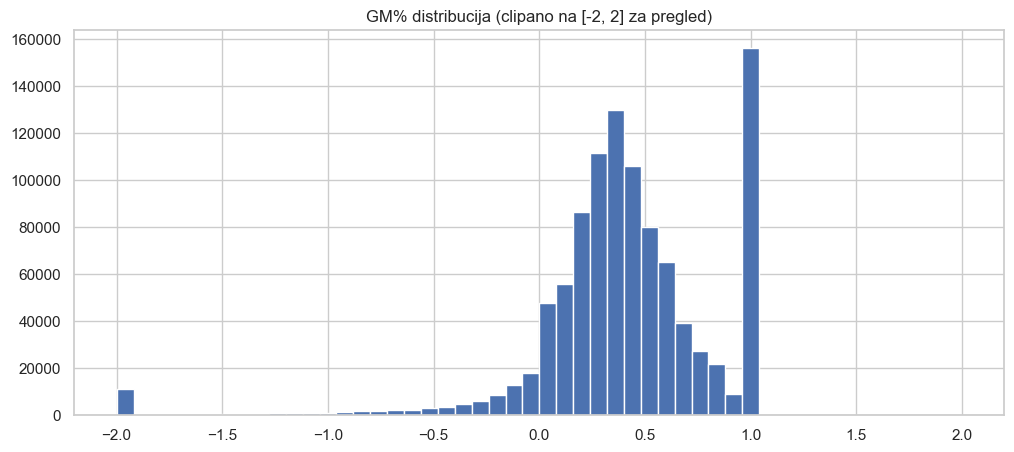

In [59]:
# Provjeri GM% distribuciju
print(df_4['GM%'].describe())
print(f'\nBroj null GM%: {df_4["GM%"].isna().sum()}')
print(f'\nBroj GM% > 1: {(df_4["GM%"] > 1).sum()}')
print(f'Broj GM% < -1: {(df_4["GM%"] < -1).sum()}')
print(f'Broj GM% < -5: {(df_4["GM%"] < -5).sum()}')
print(f'Broj GM% < -10: {(df_4["GM%"] < -10).sum()}')

import matplotlib.pyplot as plt
df_4['GM%'].clip(-2, 2).hist(bins=50)
plt.title('GM% distribucija (clipano na [-2, 2] za pregled)')
plt.show()

In [60]:
# Pogledaj najgore outliere
print('Najmanji GM%:')
display(df_4.nsmallest(10, 'GM%')[['Item Code', 'CustomerID', 'Invoiced price', 'Cost of part', 'GM%']])

print('\nNajveći GM%:')
display(df_4.nlargest(10, 'GM%')[['Item Code', 'CustomerID', 'Invoiced price', 'Cost of part', 'GM%']])

Najmanji GM%:


,Item Code,CustomerID,Invoiced price,Cost of part,GM%
683085,365143TM1,229575,0.0115,52080.1814,-4528710.4261
625878,358421TM1,229575,0.0114,46531.3860,-4081699.5263
715965,F18281-000-AA,108464,0.0100,6205.4715,-620546.1500
715966,F18281-000-AA,108464,0.0100,6205.4715,-620546.1500
908192,360756TM1,229575,0.0114,4653.1386,-408169.0526
577193,356234TM1,229395,0.0100,3098.1000,-309809.0000
183727,363683TM1,222134,0.0118,2174.8684,-184309.8814
1066586,416922TM1,222134,0.0118,2065.4000,-175032.8983
715971,F18281-000-AA,108464,0.0100,1227.8800,-122787.0000
1208323,365096,226113,0.0011,75.3220,-68473.5455



Najveći GM%:


,Item Code,CustomerID,Invoiced price,Cost of part,GM%
711558,2356-168,298276,31.7800,-3718.5738,118.0099
293501,PACA3311912400,2028,15.1700,-52.4300,4.4562
1077256,PACA3311912400,2028,15.1700,-52.1640,4.4386
68870,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
225463,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
519728,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
593567,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
822861,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
906057,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
1006113,YB42-F1732-00,2042,1.7850,-2.4658,2.3814


In [63]:
raw_path = '../data/raw/LUMEN_DS.csv'
converted_path1 = '../data/raw/data1.csv'

if not os.path.exists(converted_path1):
    with open(raw_path, 'r', encoding='utf-16') as file:
        data = file.read()
    
    data = data.replace('"', '')
    
    with open(converted_path1, 'w', encoding='utf-8') as file:
        file.write(data)
    
    print('Konverzija gotova -> data1.csv')
else:
    print('data1.csv već postoji, preskačem konverziju')

DATE_COLS = [
    'Invoice Date',
    'Order Date',
    'Customer First Invoice Date',
    'Price last modified date in the ERP',
    'Born on date'
]

df1 = pd.read_csv(
    '../data/raw/data1.csv',
    encoding='utf-8',
    sep='|',
    low_memory=False,
    parse_dates=DATE_COLS
)

print(df1.shape)

# Pogledaj najgore outliere na početnim podacima
print('Najmanji GM%:')
display(df1.nsmallest(10, 'GM%')[['Item Code', 'CustomerID', 'Invoiced price', 'Cost of part', 'GM%']])

print('\nNajveći GM%:')
display(df1.nlargest(10, 'GM%')[['Item Code', 'CustomerID', 'Invoiced price', 'Cost of part', 'GM%']])

data1.csv već postoji, preskačem konverziju
(1294962, 33)
Najmanji GM%:


,Item Code,CustomerID,Invoiced price,Cost of part,GM%
683085,365143TM1,229575,0.0115,52080.1814,-4528710.4261
625878,358421TM1,229575,0.0114,46531.3860,-4081699.5263
715965,F18281-000-AA,108464,0.0100,6205.4715,-620546.1500
715966,F18281-000-AA,108464,0.0100,6205.4715,-620546.1500
908192,360756TM1,229575,0.0114,4653.1386,-408169.0526
577193,356234TM1,229395,0.0100,3098.1000,-309809.0000
1067162,317461TM2,230027,0.0100,2353.7957,-235378.5700
183727,363683TM1,222134,0.0118,2174.8684,-184309.8814
82195,317461TM1,230027,0.0100,1765.3468,-176533.6800
1066586,416922TM1,222134,0.0118,2065.4000,-175032.8983



Najveći GM%:


,Item Code,CustomerID,Invoiced price,Cost of part,GM%
884808,004367,217124,-0.0022,15.1391,6882.4091
29223,032647,216863,-0.0102,1.9863,195.7353
711558,2356-168,298276,31.7800,-3718.5738,118.0099
567320,700287,217288,-0.0130,0.2868,23.0615
1154079,700287,217288,-0.0330,0.2868,9.6909
753037,700190,217288,-0.0300,0.2128,8.0933
293501,PACA3311912400,2028,15.1700,-52.4300,4.4562
1077256,PACA3311912400,2028,15.1700,-52.1640,4.4386
68870,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
225463,YB42-F1732-00,2042,1.7850,-2.4658,2.3814


In [64]:
df_4['GM%'] = df_4['GM%'].clip(-5, 1)

print('Nakon winsorize:')
print(df_4['GM%'].describe())

Nakon winsorize:
count   1014316.0000
mean          0.3866
std           0.5929
min          -5.0000
25%           0.2270
50%           0.3977
75%           0.6381
max           1.0000
Name: GM%, dtype: float64


In [65]:
df_4.to_csv('../data/processed/data_clean_v1.csv', index=False)
print(f'Spremljeno! Shape: {df_4.shape}')

Spremljeno! Shape: (1079757, 24)


---
## 5. Popunjavanje nedostajućih vrijednosti

In [ ]:
# Zamijeni prazne stringove s NaN za konzistentnost
df = df.replace('', np.nan)

# Kategorički stupci — popuni s 'Unknown'
fill_unknown = [
    'Customer Region',
    'Product group',
    'Make vs Buy',
    'Sales Channel - Internal',
    'Sales Channel - External',
    'Manufacturing Region',
    'Manufacturing Location Code',
    'Customer industry'
]

for col in fill_unknown:
    if col in df.columns:
        n_filled = df[col].isna().sum()
        df[col] = df[col].fillna('Unknown')
        if n_filled > 0:
            print(f'{col}: popunjeno {n_filled} redova s "Unknown"')

# Numerički stupci — popuni s medianom (robustnije od meana)
num_cols_to_fill = ['Cost of part', 'Invoiced price (TX)']
for col in num_cols_to_fill:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        median_val = df[col].median()
        n_filled = df[col].isna().sum()
        df[col] = df[col].fillna(median_val)
        if n_filled > 0:
            print(f'{col}: popunjeno {n_filled} redova s medianom ({median_val:.4f})')

print('\nNedostajuće vrijednosti nakon popunjavanja:')
print(df.isnull().sum()[df.isnull().sum() > 0])

---
## 6. Enkodiranje kategoričkih varijabli

Za ML modele trebamo numeričke vrijednosti. Koristimo dvije strategije:
- **Label encoding** za ordinalne ili visoko-kardinalne varijable
- **One-hot encoding** za nisko-kardinalne (< 10 kategorija)

In [ ]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

# --- LABEL ENCODING (visoka kardinalnost ili redoslijed nije bitan) ---
label_encode_cols = [
    'CustomerID',
    'Item Code',
    'Manufacturing Location Code',
    'Sales Channel - Internal',
    'Sales Channel - External',
    'Top Customer Group',    # OTHER=0, STAR=1
    'Intercompany',          # NO=0, YES=1
    'Make vs Buy',           # BUY=0, MANUFACTURED=1
]

le_dict = {}  # spremamo enkodere za inverse_transform kasnije

for col in label_encode_cols:
    if col in df_encoded.columns:
        le = LabelEncoder()
        df_encoded[col + '_enc'] = le.fit_transform(df_encoded[col].astype(str))
        le_dict[col] = le
        print(f'{col}: {df_encoded[col].nunique()} kategorija → label encoded')

# --- ONE-HOT ENCODING (niska kardinalnost) ---
ohe_cols = [
    'Manufacturing Region',   # North America, Asia, Europe
    'Customer Region',        # North America, Asia, Europe  
    'Product family',         # PF000, PF001, PF002
]

for col in ohe_cols:
    if col in df_encoded.columns:
        dummies = pd.get_dummies(df_encoded[col], prefix=col, drop_first=False)
        df_encoded = pd.concat([df_encoded, dummies], axis=1)
        print(f'{col}: one-hot → {dummies.shape[1]} novih stupaca')

print(f'\nShape nakon enkodiranja: {df_encoded.shape}')

In [ ]:
# Customer industry enkodiranje (IC000, IC001... → numerički)
# Izvuci broj iz stringa
if 'Customer industry' in df_encoded.columns:
    df_encoded['customer_industry_num'] = (
        df_encoded['Customer industry']
        .str.extract(r'(\d+)')
        .astype(float)
    )
    print('Customer industry → customer_industry_num ✓')
    print(df_encoded['customer_industry_num'].value_counts())

---
## 7. Feature Engineering — izvedene značajke

Ovo je ključni korak — kreiramo varijable koje modelu daju kontekst o kupcu i ponašanju.

In [ ]:
# 7a. Vremenski featuri iz Invoice Date
df_encoded['invoice_year'] = df_encoded['Invoice Date'].dt.year
df_encoded['invoice_month'] = df_encoded['Invoice Date'].dt.month
df_encoded['invoice_quarter'] = df_encoded['Invoice Date'].dt.quarter
df_encoded['invoice_dayofweek'] = df_encoded['Invoice Date'].dt.dayofweek

print('Vremenski featuri dodani ✓')

In [ ]:
# 7b. Customer tenure — koliko dugo je kupac aktivan (u danima)
reference_date = df_encoded['Invoice Date'].max()
df_encoded['customer_tenure_days'] = (
    reference_date - df_encoded['Customer First Invoice Date']
).dt.days

print('Customer tenure izračunat ✓')
print(df_encoded['customer_tenure_days'].describe())

In [ ]:
# 7c. Revenue po liniji (qty * price)
df_encoded['line_revenue'] = (
    df_encoded['Invoiced qty (shipped)'] * df_encoded['Invoiced price']
)

# 7d. Gross profit po liniji
df_encoded['line_gross_profit'] = df_encoded['line_revenue'] * df_encoded['GM%']

print('Revenue i gross profit featuri dodani ✓')

In [ ]:
# 7e. Customer-level aggregate featuri
# Ovo je srž za customer segmentaciju!
customer_agg = df_encoded.groupby('CustomerID').agg(
    total_revenue=('line_revenue', 'sum'),
    total_orders=('Invoice #', 'nunique'),
    total_items=('Item Code', 'nunique'),
    avg_order_value=('line_revenue', 'mean'),
    avg_gm=('GM%', 'mean'),
    n_product_families=('Product family', 'nunique'),
    n_product_groups=('Product group', 'nunique'),
    customer_tenure_days=('customer_tenure_days', 'first'),
    customer_region=('Customer Region', 'first'),
    customer_industry=('Customer industry', 'first'),
    top_customer_group=('Top Customer Group', 'first'),
).reset_index()

print(f'Customer aggregate tablica: {customer_agg.shape}')
display(customer_agg.head())

In [ ]:
# 7f. Vizualizacija distribucija ključnih featura
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

customer_agg['total_revenue'].apply(lambda x: np.log1p(x)).hist(
    bins=40, ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Log(Total Revenue) po kupcu')

customer_agg['total_orders'].hist(bins=40, ax=axes[0,1], color='steelblue')
axes[0,1].set_title('Broj narudžbi po kupcu')

customer_agg['total_items'].hist(bins=40, ax=axes[0,2], color='steelblue')
axes[0,2].set_title('Broj unikatnih proizvoda po kupcu')

customer_agg['avg_gm'].hist(bins=40, ax=axes[1,0], color='salmon')
axes[1,0].set_title('Prosječni GM% po kupcu')

customer_agg['customer_tenure_days'].hist(bins=40, ax=axes[1,1], color='steelblue')
axes[1,1].set_title('Customer Tenure (dani)')

customer_agg['n_product_groups'].hist(bins=30, ax=axes[1,2], color='green', alpha=0.7)
axes[1,2].set_title('Broj product grupe po kupcu')

plt.suptitle('Distribucije ključnih customer featura', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
# 7g. Product co-occurrence matrica (osnova za cross-sell)
# Grupiraj po Invoice # — koji proizvodi se pojavljuju na istoj fakturi?
invoice_items = df_encoded.groupby('Invoice #')['Product group'].apply(
    lambda x: list(x.dropna().unique())
).reset_index()
invoice_items.columns = ['invoice_id', 'product_groups']

# Filtriraj fakture s više od jednog produkta (cross-sell prilike)
multi_product = invoice_items[invoice_items['product_groups'].apply(len) > 1]
print(f'Fakture s 1 produktom: {(invoice_items["product_groups"].apply(len) == 1).sum():,}')
print(f'Fakture s 2+ produkata: {len(multi_product):,}')
print(f'% multi-product faktura: {len(multi_product)/len(invoice_items)*100:.1f}%')
display(multi_product.head(5))

---
## 8. Korelacijska analiza numeričkih featura

In [ ]:
num_features = [
    'Invoiced qty (shipped)', 'Invoiced price', 'Cost of part',
    'GM%', 'line_revenue', 'customer_tenure_days',
    'invoice_month', 'invoice_quarter'
]

existing_num = [c for c in num_features if c in df_encoded.columns]
corr = df_encoded[existing_num].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5)
plt.title('Korelacijska matrica numeričkih featura')
plt.tight_layout()
plt.show()

---
## 9. Finalni dataset — spremi za modeliranje

In [ ]:
# Finalni pregled
print('=== FINALNI DATASET ===')
print(f'Shape: {df_encoded.shape}')
print(f'Nullovi: {df_encoded.isnull().sum().sum()}')
print(f'\nStupci:')
for col in df_encoded.columns:
    print(f'  {col}: {df_encoded[col].dtype}')

In [ ]:
# Spremi očišćeni dataset
df_encoded.to_csv('../data/processed/data_clean.csv', index=False)
customer_agg.to_csv('../data/processed/customer_features.csv', index=False)
invoice_items.to_csv('../data/processed/invoice_items.csv', index=False)

print('Spremljeno ✓')
print('  → data/processed/data_clean.csv')
print('  → data/processed/customer_features.csv')
print('  → data/processed/invoice_items.csv')

---
## Sažetak — što smo napravili

| Korak | Akcija |
|-------|--------|
| Stupci | Uklonili smo 12 redudantnih stupaca (cleaner.py) |
| Intercompany | Filtrirali smo Intercompany=YES transakcije van modela |
| Redovi | Uklonili smo redove bez Item Code / CustomerID / Invoiced price |
| Redovi | Uklonili smo negativne cijene i količine (credit note-ovi) |
| GM% | Winsorized na [-5, 1] za outliere |
| Nullovi | Kategorički → 'Unknown', numerički → medijan |
| Enkodiranje | Label encoding za visoko-kardinalne, OHE za nisko-kardinalne |
| Novi featuri | Tenure, revenue, gross profit, vremenski featuri |
| Agregati | Customer-level tablica za segmentaciju |
| Co-occurrence | Invoice-items tablica za market basket analysis |

**Sljedeći korak → `02_customer_segmentation.ipynb`**